![Tutorial_banner](images/cbens_2026_performancetutorial_logo.jpg)

# Tutorial 1 — Dos dados meteorológicos aos primeiros modelos com pvlib

**CBENS 2026 | PV Performance Modeling in Practice**

**Objetivo:** aprender a ler e usar funções do `pvlib`. Hoje seguiremos este caminho:

**Localização → posição solar → irradiância (céu claro ou dados meteorológicos) → irradiância no plano do módulo → temperatura da célula.**

A potência elétrica e a energia produzida ficam para o **Tutorial 2**. O objetivo aqui é entender o que entra e o que sai de cada função.

*Pré-requisito:* o tutorial de dados meteorológicos apresenta GHI, DNI e DHI em mais detalhe; aqui vamos utilizar essas variáveis em um modelo.

## 1. Como ler um notebook e uma função

Células de **texto** explicam os conceitos; células de **código** executam comandos. Use `Shift + Enter` para executar a célula.

Em uma função, os **argumentos** são as informações que fornecemos; o **retorno** é o resultado que podemos guardar em uma variável e reutilizar.

In [4]:
def reta(x, m, b):
    return m * x + b

resultado = reta(x=5, m=2, b=1)
print("Resultado:", resultado)

Resultado: 11


**Pergunte ao grupo:** quais são as entradas? Qual é a saída? O que muda se alterarmos `m`? 

O mesmo padrão aparece nas funções de modelagem: `resultado = funcao(entrada_1=..., entrada_2=...)`.

Para descobrir o que uma função recebe, consulte sua [documentação](https://pvlib-python.readthedocs.io/en/stable/reference/index.html), use `help(funcao)` ou digite `funcao?` no Jupyter.

## 2. Bibliotecas que vamos utilizar

- `pandas`: séries temporais e tabelas (`DataFrame`).
- `matplotlib`: visualização.
- `pvlib`: cálculos de posição solar, irradiância, temperatura e desempenho FV.

Em **Binder**, as dependências vêm de `requirements.txt`. Em **Colab**, podemos instalar pacotes caso não estejam disponíveis.

In [5]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("pvlib") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "pvlib>=0.13"])

import pandas as pd
import matplotlib.pyplot as plt
import pvlib
from pathlib import Path

print("pvlib:", pvlib.__version__)

pvlib: 0.16.1


## 3. Primeira pergunta: como conhecer a irradiância em um lugar?

Imagine que temos somente a **latitude, longitude e data**, sem medições meteorológicas. Podemos começar com um **modelo de céu claro**: estima a irradiância em condições ideais de ausência de nuvens. **Não é uma previsão do tempo real.**

Vamos usar como exemplo **Niterói, Rio de Janeiro** (coordenadas aproximadas).

### Função 1 — `pvlib.location.Location()`

**Entradas principais**

- `latitude`, `longitude`: coordenadas em graus (sul e oeste com sinal negativo).
- `tz`: fuso horário da localização.
- `name`: nome opcional.

**Saída:** um objeto `Location`, que reúne dados geográficos e fornece métodos como `get_solarposition()` e `get_clearsky()`.

[Documentação: Location](https://pvlib-python.readthedocs.io/en/stable/reference/generated/pvlib.location.Location.html)

In [6]:
 pvlib.location.Location?

Init signature:
pvlib.location.Location(
    latitude,
    longitude,
    tz='UTC',
    altitude=None,
    name=None,
)
Docstring:     
Location objects are convenient containers for latitude, longitude,
time zone, and altitude data associated with a particular geographic
location. You can also assign a name to a location object.

Location objects have a time-zone attribute ``tz`` (IANA timezone string).

.. deprecated:: 0.15.2

   The ``pytz`` attribute is deprecated. Use ``tz`` instead.

Location objects support the print method.

Parameters
----------
latitude : float.
    Positive is north of the equator.
    Use decimal degrees notation.

longitude : float.
    Positive is east of the prime meridian.
    Use decimal degrees notation.

tz : time zone as str, int, float, or datetime.tzinfo, default 'UTC'.
    See http://en.wikipedia.org/wiki/List_of_tz_database_time_zones for a
    list of valid name strings. An ``int`` or ``float`` must be a
    whole-number hour offsets from UTC t

In [7]:
local = pvlib.location.Location(
    latitude=-22.905,
    longitude=-43.122,
    tz="America/Sao_Paulo",
    name="Niteroi"
)

print(local)

Location: 
  name: Niteroi
  latitude: -22.905
  longitude: -43.122
  altitude: -2.0
  tz: America/Sao_Paulo


### Construindo um índice de tempo com pandas

`pd.date_range()` gera uma sequência de datas e horas. Ela tem um início (`start`), um fim (`end`), a frequência (`freq`) e um fuso (`tz`). 

**Atenção:** pvlib calcula a posição solar no instante fornecido

In [8]:
times = pd.date_range(
    start="2026-10-26 00:00", end="2026-10-26 23:55",
    freq="5min", tz=local.tz
)

print("Primeiros horários:", times[:3])
print("Número de horários:", len(times))

Primeiros horários: DatetimeIndex(['2026-10-26 00:00:00-03:00', '2026-10-26 00:05:00-03:00',
               '2026-10-26 00:10:00-03:00'],
              dtype='datetime64[ns, America/Sao_Paulo]', freq='5min')
Número de horários: 288


### Função 2 — `local.get_solarposition(times)`

**Entrada:** a sequência de instantes (`times`).

**Saída:** uma tabela com **ângulos solares** para cada instante, incluindo `apparent_zenith` e `azimuth`. A geometria solar é uma das entradas de cálculos posteriores.

[Documentação: get_solarposition](https://pvlib-python.readthedocs.io/en/stable/reference/generated/pvlib.location.Location.get_solarposition.html)

,apparent_zenith,azimuth
2026-10-26 00:00:00-03:00,144.217851,170.154142
2026-10-26 00:05:00-03:00,143.999502,168.105205
2026-10-26 00:10:00-03:00,143.741113,166.081493
2026-10-26 00:15:00-03:00,143.443534,164.086572
2026-10-26 00:20:00-03:00,143.107715,162.123649


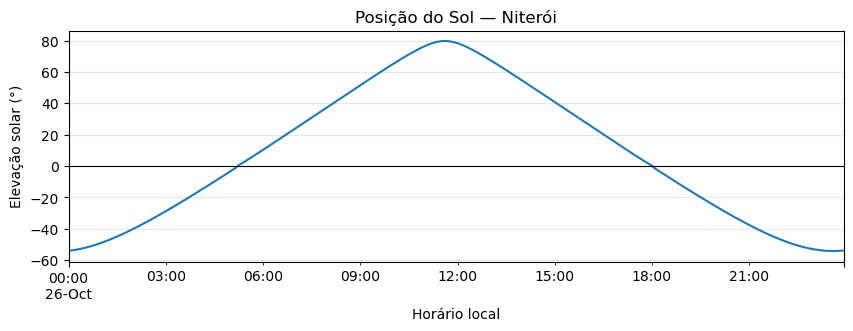

In [9]:
solar_position = local.get_solarposition(times)
display(solar_position[["apparent_zenith", "azimuth"]].head())

ax = solar_position["apparent_elevation"].plot(figsize=(10, 3))
ax.axhline(0, color="black", linewidth=0.8)
ax.set(ylabel="Elevação solar (°)", xlabel="Horário local", title="Posição do Sol — Niterói")
ax.grid(alpha=0.3)
plt.show()

### Função 3 — `local.get_clearsky(times)`

**Entrada:** novamente `times`. O objeto `local` já conhece a localização.

**Saída:** um `DataFrame` de irradiância de céu claro com as colunas `ghi`, `dni` e `dhi`, em W/m².

[Documentação: get_clearsky](https://pvlib-python.readthedocs.io/en/stable/reference/generated/pvlib.location.Location.get_clearsky.html)

,ghi,dni,dhi
2026-10-26 00:00:00-03:00,0.0,0.0,0.0
2026-10-26 00:05:00-03:00,0.0,0.0,0.0
2026-10-26 00:10:00-03:00,0.0,0.0,0.0
2026-10-26 00:15:00-03:00,0.0,0.0,0.0
2026-10-26 00:20:00-03:00,0.0,0.0,0.0


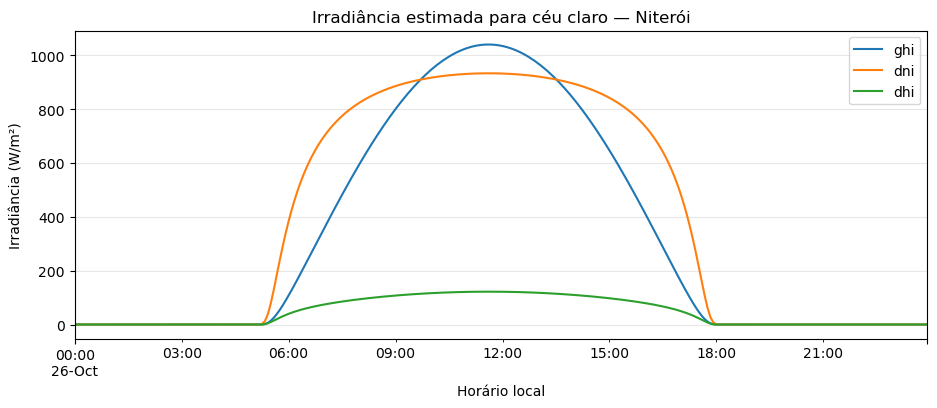

In [10]:
clearsky = local.get_clearsky(times)
display(clearsky.head())

ax = clearsky[["ghi", "dni", "dhi"]].plot(figsize=(11, 4))
ax.set(title="Irradiância estimada para céu claro — Niterói",
       xlabel="Horário local", ylabel="Irradiância (W/m²)")
ax.grid(alpha=0.3)
plt.show()

**Para discutir:** por que as três curvas são diferentes? O que esperaríamos ver em um dia nublado? Como `get_clearsky()` saberia se está chovendo? (Não saberia.)

**Mini-exercício:** mude a data ou a localização. Execute novamente as duas células anteriores e compare os resultados.

## 4. Quando temos dados meteorológicos reais ou estimados

Para modelar a produção de uma usina existente, usamos normalmente uma **série meteorológica** que represente suas condições de operação. Neste curso, a fonte será o **NSRDB (National Solar Radiation Database)**.

1. Abra o [site do NSRDB](https://nsrdb.nrel.gov/) e explore a documentação e as opções de acesso aos dados.
2. Localize a usina **Simon Solar** aproximadamente em `33.6762, -83.67633` (Geórgia, EUA).
3. Observe que a base apresenta irradiância e outras variáveis meteorológicas. O arquivo disponível no repositório já reúne **2016–2023**, sem exigir que todos façam solicitações simultâneas à API.

**Site / documentação:** [NSRDB](https://nsrdb.nrel.gov/) · [Leitura de dados meteorológicos com pvlib](https://pvlib-python.readthedocs.io/en/stable/user_guide/weather_data.html)

**Importante:** o NSRDB contém estimativas meteorológicas, não medições de todos os sensores da usina. Compararemos esses dados com medições de campo mais tarde.

### Encontrando os arquivos no Binder ou Colab

- **Binder:** o repositório do GitHub é incluído na sessão, inclusive as pastas `weather_data/` e `field_data/`, quando estão versionadas.
- **Colab:** abrir um notebook pelo GitHub **não** baixa automaticamente as outras pastas. A célula abaixo clona o repositório caso o arquivo meteorológico não esteja disponível.

Para funcionar nos dois ambientes, usaremos caminhos relativos. Uma conexão à internet é necessária apenas se for preciso clonar o repositório.

In [12]:
import os

weather_path = Path("weather_data/nsrdb_33.6762_-83.67633_nsrdb-GOES-aggregated-v4-0-0_60_2016.csv")

if not weather_path.exists() and Path("/content").exists():
    repo = Path("/content/2026_pvlib-and-performance_CBENS")
    if not repo.exists():
        subprocess.check_call([
            "git", "clone", "--depth", "1",
            "https://github.com/PV-Tutorials/2026_pvlib-and-performance_CBENS.git",
            str(repo)
        ])
    os.chdir(repo)
    weather_path = Path("weather_data/nsrdb_33.6762_-83.67633_nsrdb-GOES-aggregated-v4-0-0_60_2016.csv")

if not weather_path.exists():
    raise FileNotFoundError(
        f"Arquivo não encontrado: {weather_path}. Confirme que weather_data/ está no repositório."
    )

print("Arquivo encontrado:", weather_path)

Arquivo encontrado: weather_data\nsrdb_33.6762_-83.67633_nsrdb-GOES-aggregated-v4-0-0_60_2016.csv


### Função 4 — `pvlib.iotools.read_nsrdb_psm4()`

**Entrada:** caminho do arquivo meteorológico NSRDB no formato PSM4.

**Saída:**
- weather: um DataFrame com os dados meteorológicos e um índice temporal.
- weather_meta: um dicionário com os metadados do arquivo, como latitude, longitude e fuso horário.
O argumento map_variables=True converte os nomes das variáveis para o padrão utilizado pelo pvlib (por exemplo, Temperature → temp_air).

Diferentemente de pd.read_csv(), essa função interpreta automaticamente a estrutura e os metadados dos arquivos originais NSRDB PSM4.

In [13]:
weather, weather_meta = pvlib.iotools.read_nsrdb_psm4(
    weather_path, map_variables=True
)

weather = weather.sort_index()

display(weather[["ghi", "dni", "dhi", "temp_air", "wind_speed"]].head())
print("Início:", weather.index.min())
print("Fim:", weather.index.max())
print("Minutos encontrados:", sorted(weather.index.minute.unique()))
display(weather_meta)

,ghi,dni,dhi,temp_air,wind_speed
2016-01-01 00:30:00-05:00,0.0,0.0,0.0,8.8,0.5
2016-01-01 01:30:00-05:00,0.0,0.0,0.0,8.3,0.5
2016-01-01 02:30:00-05:00,0.0,0.0,0.0,7.7,0.5
2016-01-01 03:30:00-05:00,0.0,0.0,0.0,7.0,0.5
2016-01-01 04:30:00-05:00,0.0,0.0,0.0,6.3,0.5


Início: 2016-01-01 00:30:00-05:00
Fim: 2016-12-31 23:30:00-05:00
Minutos encontrados: [30]


{'Source': 'NSRDB',
 'Location ID': '985762',
 'City': '-',
 'State': '-',
 'Country': '-',
 'Time Zone': -5,
 'Local Time Zone': -5,
 'Clearsky DHI Units': 'w/m2',
 'Clearsky DNI Units': 'w/m2',
 'Clearsky GHI Units': 'w/m2',
 'Dew Point Units': 'c',
 'DHI Units': 'w/m2',
 'DNI Units': 'w/m2',
 'GHI Units': 'w/m2',
 'Solar Zenith Angle Units': 'Degree',
 'Temperature Units': 'c',
 'Pressure Units': 'mbar',
 'Relative Humidity Units': '%',
 'Precipitable Water Units': 'cm',
 'Wind Direction Units': 'Degrees',
 'Wind Speed Units': 'm/s',
 'Cloud Type -15': '',
 'Cloud Type 0': 'Clear',
 'Cloud Type 1': 'Probably Clear',
 'Cloud Type 2': 'Fog',
 'Cloud Type 3': 'Water',
 'Cloud Type 4': 'Super-Cooled Water',
 'Cloud Type 5': 'Mixed',
 'Cloud Type 6': 'Opaque Ice',
 'Cloud Type 7': 'Cirrus',
 'Cloud Type 8': 'Overlapping',
 'Cloud Type 9': 'Overshooting',
 'Cloud Type 10': 'Unknown',
 'Cloud Type 11': 'Dust',
 'Cloud Type 12': 'Smoke',
 'Fill Flag 0': '',
 'Fill Flag 1': 'Missing Image',


**Observe:** GHI, DNI e DHI representam a irradiância disponível; `temp_air` representa a temperatura ambiente (°C); `wind_speed` é a velocidade do vento (m/s). Os horários deste arquivo NSRDB estão em **HH:30**, no fuso fixo UTC−5.

Agora escolha uma semana e visualize como o tempo real difere do perfil ideal de céu claro.

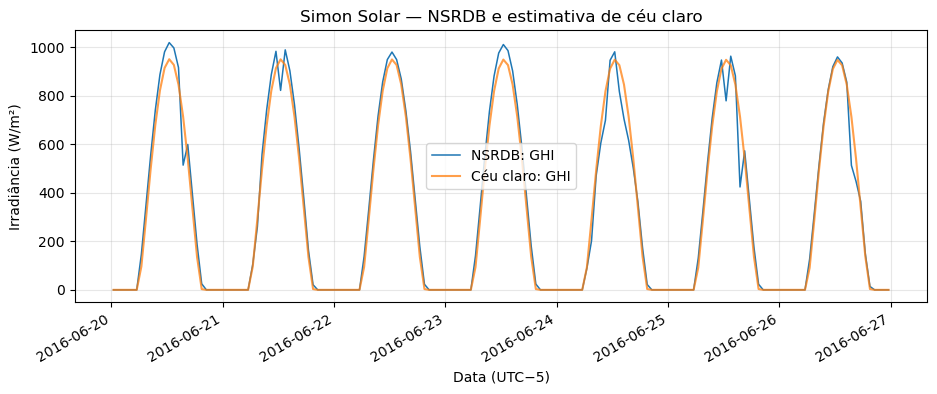

In [15]:
site = pvlib.location.Location(33.6762, -83.67633, tz="Etc/GMT+5", name="Simon Solar")
week = weather.loc["2016-06-20":"2016-06-26", ["ghi", "dni", "dhi", "temp_air", "wind_speed"]]
clear_week = site.get_clearsky(week.index)

ax = week["ghi"].plot(figsize=(11, 4), label="NSRDB: GHI", linewidth=1.1)
clear_week["ghi"].plot(ax=ax, label="Céu claro: GHI", alpha=0.75)
ax.set(xlabel="Data (UTC−5)", ylabel="Irradiância (W/m²)",
       title="Simon Solar — NSRDB e estimativa de céu claro")
ax.legend(); ax.grid(alpha=0.3); plt.show()

## 5. Da irradiância horizontal à irradiância recebida pelo módulo

O módulo FV não está necessariamente deitado na horizontal. Precisamos transformar GHI, DNI e DHI em **irradiância no plano do módulo (POA)**.

### Função 5 — `pvlib.irradiance.get_total_irradiance()`

**Entradas:**
- Geometria do módulo: `surface_tilt` (inclinação) e `surface_azimuth` (orientação).
- Geometria solar: `solar_zenith`, `solar_azimuth`.
- Dados meteorológicos: `dni`, `ghi`, `dhi`.
- Opcional: `albedo` e `model` de transposição.

**Saída:** tabela com `poa_global` e componentes da irradiância incidente no plano.

[Documentação: get_total_irradiance](https://pvlib-python.readthedocs.io/en/stable/reference/generated/pvlib.irradiance.get_total_irradiance.html)

,poa_global,poa_direct,poa_diffuse,poa_sky_diffuse,poa_ground_diffuse
2016-06-20 00:30:00-05:00,0.0,0.0,0.0,0.0,0.0
2016-06-20 01:30:00-05:00,0.0,0.0,0.0,0.0,0.0
2016-06-20 02:30:00-05:00,0.0,0.0,0.0,0.0,0.0
2016-06-20 03:30:00-05:00,0.0,0.0,0.0,0.0,0.0
2016-06-20 04:30:00-05:00,0.0,0.0,0.0,0.0,0.0


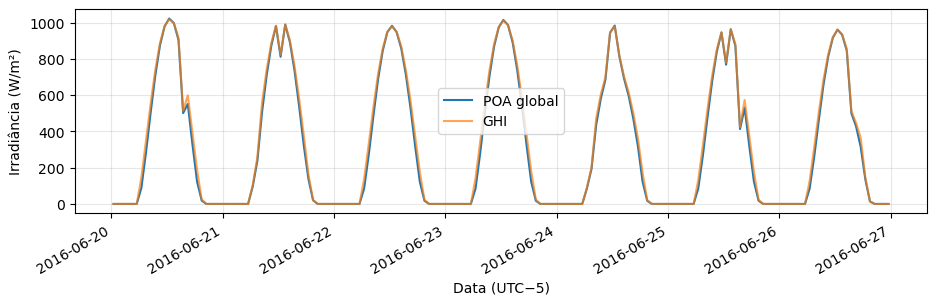

In [16]:
solar_site = site.get_solarposition(week.index)

poa = pvlib.irradiance.get_total_irradiance(
    surface_tilt=20,
    surface_azimuth=180,
    solar_zenith=solar_site["apparent_zenith"],
    solar_azimuth=solar_site["azimuth"],
    dni=week["dni"], ghi=week["ghi"], dhi=week["dhi"],
    albedo=0.20, model="isotropic"
)

display(poa.head())
ax = poa["poa_global"].plot(figsize=(11, 3), label="POA global")
week["ghi"].plot(ax=ax, label="GHI", alpha=0.7)
ax.set(xlabel="Data (UTC−5)", ylabel="Irradiância (W/m²)")
ax.legend(); ax.grid(alpha=0.3); plt.show()

**Pergunta:** de onde vieram os parâmetros `surface_tilt=20` e `surface_azimuth=180`? Eles descrevem a instalação — **não** são calculados pela função.

**Experimente:** altere `surface_tilt` para `0` e compare POA e GHI. A igualdade não é exata em todas as condições/modelos, mas esperamos um comportamento semelhante para um plano horizontal.

## 6. Como estimar a temperatura da célula FV?

A temperatura da célula afeta o desempenho elétrico. Ela depende, entre outros fatores, da irradiância recebida, da **temperatura do ar** e do **vento**.

### Função 6 — `pvlib.temperature.sapm_cell()`

**Entradas:**
- `poa_global`: irradiância no plano do módulo (W/m²), calculada na etapa anterior.
- `temp_air`: temperatura ambiente (°C), do NSRDB.
- `wind_speed`: velocidade do vento (m/s), do NSRDB.
- `a`, `b`, `deltaT`: coeficientes de um modelo térmico (neste exemplo, `open_rack_glass_glass`).

**Saída:** uma série com a temperatura estimada da **célula** (°C).

[Documentação: sapm_cell](https://pvlib-python.readthedocs.io/en/stable/reference/generated/pvlib.temperature.sapm_cell.html)

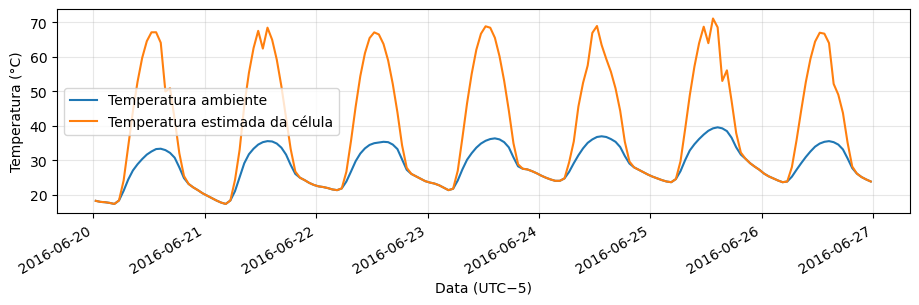

In [17]:
temp_params = pvlib.temperature.TEMPERATURE_MODEL_PARAMETERS["sapm"]["open_rack_glass_glass"]

cell_temperature = pvlib.temperature.sapm_cell(
    poa_global=poa["poa_global"],
    temp_air=week["temp_air"],
    wind_speed=week["wind_speed"],
    **temp_params
)

ax = week["temp_air"].plot(figsize=(11, 3), label="Temperatura ambiente")
cell_temperature.plot(ax=ax, label="Temperatura estimada da célula")
ax.set(xlabel="Data (UTC−5)", ylabel="Temperatura (°C)")
ax.legend(); ax.grid(alpha=0.3); plt.show()

### Entendendo `**temp_params`

`temp_params` é um **dicionário** com parâmetros do modelo térmico. O operador `**` passa cada item como um argumento nomeado (`a=...`, `b=...`, `deltaT=...`).

In [18]:
print(temp_params)
print("Temperatura máxima estimada da célula (°C):", round(cell_temperature.max(), 1))

{'a': -3.47, 'b': -0.0594, 'deltaT': 3}
Temperatura máxima estimada da célula (°C): 71.1


**Mini-exercício:** aumente a velocidade do vento em 2 m/s **apenas para testar a sensibilidade** (não altere os dados meteorológicos originais). Recalcule `cell_temperature` e observe o resultado.

In [20]:
# Teste de sensibilidade: vento +2 m/s. week["wind_speed"] + 2,
cell_temperature_wind2 = pvlib.temperature...



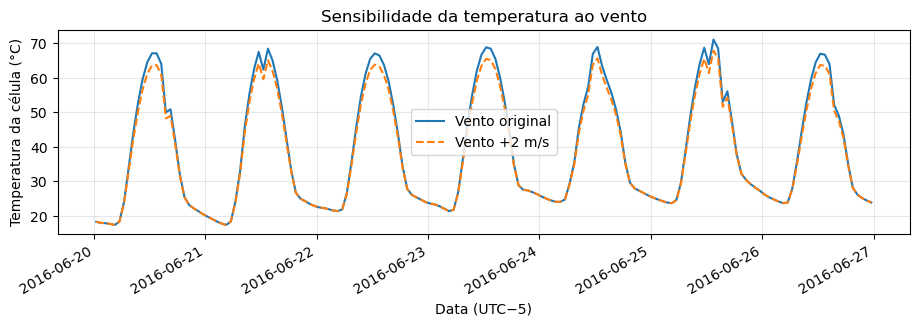

In [21]:
ax = cell_temperature.plot(figsize=(11, 3), label="Vento original")
cell_temperature_wind2.plot(ax=ax, label="Vento +2 m/s", linestyle="--")

ax.set(xlabel="Data (UTC−5)", ylabel="Temperatura da célula (°C)",
       title="Sensibilidade da temperatura ao vento")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

**Discussão:** temperatura ambiente e temperatura da célula são a mesma coisa? Qual variável precisaríamos comparar com um sensor instalado no módulo?

## 7. O que vem depois na cadeia de modelagem?

Até aqui, cada resultado foi reutilizado como entrada da função seguinte:

`localização + horários → posição solar`

`GHI + DNI + DHI + posição solar + orientação → POA`

`POA + temperatura do ar + vento → temperatura da célula`

**Próximo tutorial:** `POA + temperatura da célula + parâmetros do módulo → potência DC → perdas → inversor → potência AC → energia`.

O `pvlib` também oferece `ModelChain`, que integra muitas dessas etapas. Neste curso, começamos **com funções explícitas** para enxergar e discutir cada hipótese, cada entrada e cada saída.

**Antes de avançar, você consegue identificar:** (1) quais dados vêm de uma base meteorológica; (2) quais parâmetros descrevem a usina; e (3) quais variáveis são calculadas durante a simulação?

### Referências

- [Documentação do pvlib](https://pvlib-python.readthedocs.io/)
- [NSRDB](https://nsrdb.nrel.gov/)
- [Guia de dados meteorológicos do pvlib](https://pvlib-python.readthedocs.io/en/stable/user_guide/weather_data.html)

Material didático adaptado para o CBENS 2026.